In [10]:
import sys
sys.path.insert(0,'/Users/MY PC/OneDrive/Desktop/GaPP3/') # please set your location where you put GaPP3 directory
sys.path.insert(0,'/Users/MY PC/OneDrive/Desktop/GaPP3/gapp/')
sys.path.insert(0,'/Users/MY PC/OneDrive/Desktop/GaPP3/gapp/covfunctions/')
#print(sys.path)


In [2]:
import covfunctions
from gapp import gp,dgp
from gapp import covariance
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


In [3]:
input_file = r"C:\Users\MY PC\Downloads\PantheonPlus_SH0ES_cleaned.csv"
data = pd.read_csv(input_file, engine="python")
data.head()

,CID,IDSURVEY,zHD,zHDERR,zCMB,zCMBERR,zHEL,zHELERR,m_b_corr,m_b_corr_err_DIAG,...,PKMJDERR,NDOF,FITCHI2,FITPROB,m_b_corr_err_RAW,m_b_corr_err_VPEC,biasCor_m_b,biasCorErr_m_b,biasCor_m_b_COVSCALE,biasCor_m_b_COVADD
0,2011fe,51,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.74571,1.516210,...,0.1071,36,26.8859,0.864470,0.0991,1.4960,0.0381,0.005,1.0,0.003
1,2011fe,56,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.80286,1.517230,...,0.0579,101,88.3064,0.812220,0.0971,1.4960,-0.0252,0.003,1.0,0.004
2,2012cg,51,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.47030,0.781906,...,0.0278,165,233.5000,0.000358,0.0399,0.7134,0.0545,0.019,1.0,0.036
3,2012cg,56,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.49190,0.798612,...,0.0667,55,100.1220,0.000193,0.0931,0.7134,0.0622,0.028,1.0,0.040
4,1994DRichmond,50,0.00299,0.00084,0.00299,0.00004,0.00187,0.00004,11.52270,0.880798,...,0.0522,146,109.8390,0.988740,0.0567,0.6110,0.0650,0.009,1.0,0.006


In [4]:
#extracting distance modulus, redshift and error bars from the Pantheon data
dm = data['MU_SH0ES'].to_numpy()
dmerr = data['MU_SH0ES_ERR_DIAG'].to_numpy()
z = data['zHD'].to_numpy()

In [5]:
g1 = gp.GaussianProcess(z,dm,dmerr,covfunction=covariance.Matern92,cXstar=(0.01,2.5,200),thetatrain='False')

In [6]:
rec1, theta1 = g1.gp()

In [7]:
zrec = rec1[:,0]
y_pred = rec1[:,1]
sigma = rec1[:,2]


In [8]:
zpred = np.linspace(0,2.5,200)
print(y_pred)

[34.21245974 34.88250186 35.50329288 36.07638902 36.60351643 37.08656044
 37.52755227 37.9286533  38.29213696 38.62036847 38.91578296 39.18086214
 39.41811023 39.63002955 39.81909633 39.98773729 40.13830748 40.27306979
 40.39417664 40.50365395 40.60338788 40.69511432 40.78041122 40.86069387
 40.93721289 41.01105492 41.08314573 41.15425555 41.22500635 41.29588077
 41.36723242 41.43929723 41.51220552 41.58599462 41.6606216  41.73597607
 41.8118926  41.88816277 41.96454655 42.04078297 42.11659985 42.19172266
 42.26588231 42.33882198 42.41030288 42.48010894 42.54805058 42.61396746
 42.67773032 42.73924205 42.79843789 42.85528498 42.90978129 42.96195406
 43.0118577  43.05957139 43.1051964  43.14885316 43.19067823 43.2308212
 43.26944158 43.30670574 43.34278397 43.37784765 43.41206665 43.44560689
 43.47862815 43.51128213 43.54371074 43.57604468 43.60840228 43.64088856
 43.6735946  43.7065971  43.73995819 43.77372547 43.8079322  43.84259773
 43.87772807 43.91331652 43.94934456 43.98578273 44.

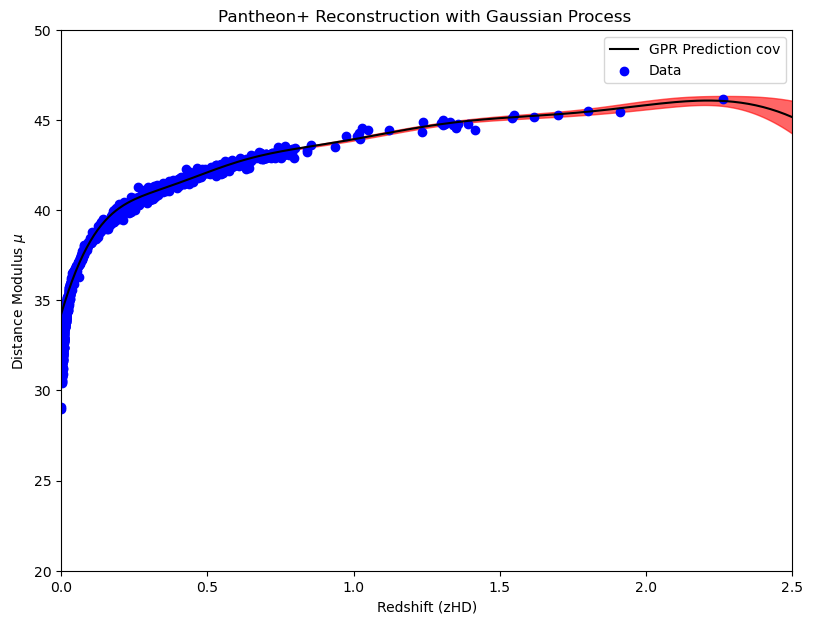

In [9]:
# Plot the results
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.ylim(20,50)
plt.xlim(0, 2.5)
plt.tight_layout()
plt.plot(zpred, y_pred, label='GPR Prediction cov', color='black')
#plt.plot(x_pred, y_pred, label='GPR Prediction', color='green')
#plt.plot(x_pred,dl,label = "Lumniosity",color = 'black')
plt.fill_between(zpred.ravel(), y_pred - sigma, y_pred + sigma, color='red', alpha=0.6)
plt.scatter(z, dm, c='b', label='Data')
plt.xlabel('Redshift (zHD)')
plt.ylabel('Distance Modulus $\mu$')
plt.title("Pantheon+ Reconstruction with Gaussian Process ")
plt.legend()
#plt.savefig('Pantheon.png', dpi=300, bbox_inches='tight')
plt.show()